# C07 — WaveDetect retrained on RAID: OG versus NS10

Retrain the WaveDetect architecture on the **exact RAID membership and train/validation/test splits used by frozen C05 Ghostbuster**. Compare the 54 original AI texts (OG) against their final attacked versions (NS10), using the same held-out human references. No NS10 text enters fitting, checkpoint selection, or threshold calibration.

Earlier `00d` and `17` used the public pretrained detector; C07 does **not** initialize from those detector weights. It initializes Qwen2.5-0.5B from its base checkpoint and a fresh ResNet-18/classifier. Stage 1 trains the CNN/head with the LM frozen; stage 2 trains all parameters. We retain the authors' Morlet transform, 16 scales, kernel 128, class-weighted loss, and 1024-token padded training representation. Fixed padding is also used at evaluation to avoid changing CNN geometry.

**Local training adaptation:** single GPU, microbatch 1, logical batch 8, gradient checkpointing, 3+3 epochs, stage learning rates 1e-3/1e-5 with linear decay. All train rows are shuffled and visited each epoch; no 90% AI undersampling. Class weights are computed over each logical batch. BatchNorm updates on microbatches, so this is an architecture-matched RAID retraining, not an exact reproduction of the authors' multi-GPU run. Select the lowest validation-loss checkpoint from stage 2 only. Test and attack scores cannot affect selection.

Source: [official WaveDetect code](https://github.com/KaitongQin/WaveDetect/tree/7975b8f46cbbd794ebdd867ae96d7dd26011cbe4), especially `model/wavedetect.py`, `model/train.py`, `model/dataset.py` and `train.sh` (Apache-2.0). The wavelet class below is copied from that revision. CNN configuration matches the released ResNet-18 configuration. The chunked vocabulary projection is algebraically the same next-token probability calculation, with fp32 log-softmax for numerical stability.

Run in a **fresh kernel** inside the reproduction project. Requires torch with CUDA, transformers, huggingface_hub, pandas, pyarrow, numpy, scikit-learn, matplotlib and tqdm. This performs actual neural detector training, which is substantially more expensive than F00. It downloads the base LM once. Latest training state is atomically saved every 10 optimizer updates and every epoch; an interruption can replay at most 9 completed updates. Each scored document is saved immediately. Rerun top-to-bottom to resume. Allow several GB of checkpoint disk space.

Outputs: `results/causal/C07_WaveDetect_RAID_OG_NS10_v1/`. No F eligibility restriction: all 54 pairs are required. This remains a development-cohort transfer stress test, not an untouched final test set.


In [1]:
from pathlib import Path
import os, json, hashlib, tempfile, io, math, random, gc, time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.checkpoint import checkpoint
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, ResNetConfig, ResNetModel
from huggingface_hub import snapshot_download
from sklearn.metrics import roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

ROOT=next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
           if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()), None)
assert ROOT is not None, 'Run inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
OUT=ROOT/'results/causal/C07_WaveDetect_RAID_OG_NS10_v1'
OUT.mkdir(parents=True,exist_ok=True)
for name in ['tokens','scores']: (OUT/name).mkdir(exist_ok=True)
SEED=20260922
BASE_LM='Qwen/Qwen2.5-0.5B'
MAX_LENGTH=1024
MICROBATCH=1
BATCH=8
EPOCHS=(3,3)
LRS=(1e-3,1e-5)
SAVE_EVERY=10
assert torch.cuda.is_available(), 'CUDA GPU required for this training configuration.'
assert torch.cuda.is_bf16_supported(), 'This configuration requires BF16 support.'
DEVICE=torch.device('cuda')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True

def digest(b): return hashlib.sha256(b).hexdigest()
def text_sha(t): return digest(str(t).encode())
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''): h.update(b)
    return h.hexdigest()
def atomic(path,writer):
    path=Path(path); fd,tmp=tempfile.mkstemp(dir=path.parent,prefix=path.name+'.',suffix='.tmp')
    try:
        with os.fdopen(fd,'wb') as f: writer(f); f.flush(); os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp): os.unlink(tmp)
def save_json(x,p): atomic(p,lambda f:f.write(json.dumps(x,sort_keys=True,indent=2,allow_nan=False).encode()))
def save_csv(df,p): atomic(p,lambda f:f.write(df.to_csv(index=False).encode()))
def save_torch(x,p): atomic(p,lambda f:torch.save(x,f))
def freeze(x,p):
    if p.exists(): assert json.loads(p.read_text())==x, f'Contract changed: use a new OUT directory ({p}).'
    else: save_json(x,p)
print('Output:',OUT)
print('GPU:',torch.cuda.get_device_name(), '| free GB:',round(torch.cuda.mem_get_info()[0]/1e9,2))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Output: ../results/causal/C07_WaveDetect_RAID_OG_NS10_v1
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU | free GB: 7.04


In [2]:
# Resolve the exact C05 data universe through saved doc keys.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
expected='raid::'+raid.source_id.astype(str)
assert keys.is_unique and set(keys)==set(expected), 'C05 dataset mismatch'
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.astype(str).str.strip().ne('').all()
assert set(raid.split)=={'train','validation','test'}
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(text_sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)

raid['pair_group_id']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('pair_group_id').split.nunique().eq(1).all(), 'Source-group split leakage'
raid['text_sha']=raid.text.map(text_sha)
assert raid.groupby('text_sha').split.nunique().eq(1).all(), 'Identical text spans multiple splits'
tr=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
va=raid.loc[raid.split.eq('validation')].sort_values('source_id').reset_index(drop=True)
assert tr.label.nunique()==va.label.nunique()==2
save_csv(raid.drop(columns='text'),OUT/'RAID_manifest.csv')
save_csv(ns[['case_id','source_id','domain','text_sha']],OUT/'NS10_manifest.csv')
display(raid.groupby(['split','label']).size().rename('n').to_frame())
print('All 54 NS10 pairs resolve to original RAID test AI; no attack fitting.')


n
split      label     
test       0      138
           1      138
train      0      636
           1      636
validation 0      135
           1      135

All 54 NS10 pairs resolve to original RAID test AI; no attack fitting.


In [3]:
# Resolve and persist one immutable base-LM snapshot revision before loading weights.
revision_path=OUT/'base_revision.json'
if revision_path.exists():
    base_revision=json.loads(revision_path.read_text())['revision']
    snapshot=Path(snapshot_download(BASE_LM,revision=base_revision))
else:
    snapshot=Path(snapshot_download(BASE_LM))
    base_revision=snapshot.name
    save_json(dict(model=BASE_LM,revision=base_revision),revision_path)
tokenizer=AutoTokenizer.from_pretrained(snapshot)
if tokenizer.pad_token_id is None: tokenizer.pad_token=tokenizer.eos_token
tokenizer.padding_side='right'
contract=dict(version='C07_v1',implementation='two_stage_chunked_qwen_resnet18_v1',
    official_commit='7975b8f46cbbd794ebdd867ae96d7dd26011cbe4',base_lm=BASE_LM,base_revision=base_revision,
    seed=SEED,max_length=MAX_LENGTH,microbatch=MICROBATCH,logical_batch=BATCH,
    epochs=list(EPOCHS),lrs=list(LRS),optimizer='AdamW native parameter dtype, eps=1e-8, weight_decay=.01',
    selection='stage2 minimum validation class-weighted loss',padding='fixed 1024 train and eval',
    probability_mask='authors attention_mask[:,:-1]',loss='authors inverse-frequency formula per logical batch',
    layout='raw saved text, no newline normalization',torch=str(torch.__version__),transformers=transformers.__version__,
    inputs={str(p.relative_to(ROOT)):file_sha(p) for p in [BASE/'fz118_paired_features.parquet',
        BASE/'paired_corpus.parquet',C05/'raid_all_features.parquet',C05/'contract.json',NSDIR/'NS10_texts.csv']})
freeze(contract,OUT/'contract.json')
CONTRACT_SHA=text_sha(json.dumps(contract,sort_keys=True))

def encode(text):
    key=text_sha(text); path=OUT/'tokens'/(key+'.pt')
    if path.exists():
        obj=torch.load(path,map_location='cpu',weights_only=True)
        assert obj['contract']==CONTRACT_SHA
        return obj
    full=tokenizer(str(text),add_special_tokens=True)['input_ids']
    assert len(full)>=2, 'Document has fewer than two tokens'
    ids=full[:MAX_LENGTH]; n=len(ids)
    obj=dict(contract=CONTRACT_SHA,input_ids=torch.tensor(ids+[tokenizer.pad_token_id]*(MAX_LENGTH-n)),
             attention_mask=torch.tensor([1]*n+[0]*(MAX_LENGTH-n)),tokens_total=len(full),tokens_used=n,
             truncated=len(full)>MAX_LENGTH)
    save_torch(obj,path); return obj
all_texts=pd.concat([raid[['text']],ns[['text']]]).drop_duplicates('text')
for t in tqdm(all_texts.text,desc='Tokenize/cache'): encode(t)
print('Base LM revision:',base_revision)


Tokenize/cache: 100%|██████████████████████████████████████████████████████████████████████████████████| 1872/1872 [00:08<00:00, 217.69it/s]

Base LM revision: 060db6499f32faf8b98477b0a26969ef7d8b9987


## Model and memory-efficient forward path
The LM starts from base pretrained weights; CNN and classifier start fresh. BF16 LM parameters match the authors' training code; CNN/head use fp32 parameters with BF16 autocast. Gradient checkpointing and chunked output projection reduce peak memory. The native optimizer state dtype is recorded in the contract. This is full stage-2 LM fine-tuning, not LoRA or threshold-only calibration.


In [4]:
class WaveletTransform(nn.Module):
    """
    Differentiable continuous wavelet transform (Morlet basis) with padding,
    cropping, and reconstruction.
    Inputs:
        token_probs (B, T)
        attention_mask (B, T) — optional but recommended
    Output:
        wavelet_spectrum (B, 1, num_scales, T)
    """
    def __init__(self, wavelet="morl", num_scales=32, kernel_size=128):
        super().__init__()
        assert wavelet == "morl", "Only Morlet wavelet is supported at this time"
        self.num_scales = num_scales
        self.kernel_size = kernel_size

        # Time axis in [-2, 2]
        self.register_buffer("time", torch.linspace(-2, 2, steps=kernel_size))
        self.sigma = 1.0
        self.freq0 = 5.0
        self.register_buffer("scales", torch.linspace(1.0, num_scales, num_scales))

    def morlet_wavelet(self, scale):
        t = self.time / scale
        wave = torch.exp(-0.5 * (t / self.sigma) ** 2) * torch.cos(2 * math.pi * self.freq0 * t)
        wave = wave / (wave.abs().sum() + 1e-6)
        return wave.view(1, 1, -1)

    def forward(self, token_probs: torch.FloatTensor, attention_mask: torch.FloatTensor = None):
        """
        token_probs: (B, T)
        attention_mask: (B, T)
        return: wavelet_spectrum (B, 1, num_scales, T)
        """
        B, T = token_probs.shape
        device = token_probs.device

        if attention_mask is not None:
            # Compute the valid sequence length for each sample
            valid_lengths = attention_mask.sum(dim=1).long()
        else:
            valid_lengths = torch.full((B,), T, dtype=torch.long, device=device)

        # ========== Wavelet transform ==========
        responses = []
        for i in range(B):
            valid_len = valid_lengths[i].item()
            x_valid = token_probs[i, :valid_len].unsqueeze(0).unsqueeze(0)  # (1, 1, valid_len)
            res_list = []
            for s in self.scales:
                kernel = self.morlet_wavelet(s.to(device)).to(x_valid.dtype)
                pad = self.kernel_size // 2
                conv_real = torch.nn.functional.conv1d(x_valid, kernel, padding=pad)
                res_list.append(conv_real)
            # Stack responses into shape (1, 1, num_scales, valid_len)
            res = torch.stack(res_list, dim=2)
            
            # Restore the original length T by padding zeros on the right
            if valid_len < T:
                pad_size = T - valid_len
                res = torch.nn.functional.pad(res, (0, pad_size))
            responses.append(res)

        responses = torch.cat(responses, dim=0)  # (B, 1, num_scales, T)
        energy = responses.abs()

        return energy



class RaidWaveDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.qwen_model=AutoModelForCausalLM.from_pretrained(snapshot,torch_dtype=torch.bfloat16,
                                                          attn_implementation='sdpa')
        self.qwen_model.config.use_cache=False
        self.qwen_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
        self.wavelet=WaveletTransform(num_scales=16,kernel_size=128)
        cfg=ResNetConfig(num_channels=3,embedding_size=64,hidden_sizes=[64,128,256,512],
                         depths=[2,2,2,2],layer_type='basic',hidden_act='relu',downsample_in_first_stage=False)
        self.cnn=ResNetModel(cfg)
        self.classifier=nn.Linear(512,2)
        self.stage=1
    def set_stage(self,stage):
        self.stage=stage
        self.qwen_model.requires_grad_(stage==2)
    def train(self,mode=True):
        super().train(mode)
        if self.stage==1: self.qwen_model.eval()
        return self
    def projected_probs(self,h,y):
        logits=self.qwen_model.lm_head(h).float()
        return logits.log_softmax(-1).gather(-1,y.unsqueeze(-1)).squeeze(-1).exp()
    def forward(self,input_ids,attention_mask):
        with torch.set_grad_enabled(self.training and self.stage==2):
            h=self.qwen_model.model(input_ids=input_ids,attention_mask=attention_mask,
                                    use_cache=False,return_dict=True).last_hidden_state[:,:-1]
            target=input_ids[:,1:]
            chunks=[]
            for start in range(0,h.shape[1],64):
                args=(h[:,start:start+64],target[:,start:start+64])
                if self.training and self.stage==2:
                    prob=checkpoint(self.projected_probs,*args,use_reentrant=False)
                else: prob=self.projected_probs(*args)
                chunks.append(prob)
            mask=attention_mask[:,:-1]
            probs=torch.cat(chunks,dim=1)*mask
        spectrum=self.wavelet(probs,mask).repeat(1,3,1,1)
        out=self.cnn(spectrum,return_dict=True).last_hidden_state.mean(dim=(2,3))
        return self.classifier(out)

model=RaidWaveDetect().to(DEVICE)
print('Parameters:',sum(p.numel() for p in model.parameters()))

def batch_inputs(frame):
    records=[encode(t) for t in frame.text]
    return {k:torch.stack([r[k] for r in records]).to(DEVICE) for k in ['input_ids','attention_mask']}

def loss_coeff(labels):
    # Exact authors' loss: sum_c [N/(2*n_c)] * mean(losses in class c).
    # This is not the usual sample-weighted CE. Compute once per logical batch.
    n=len(labels);counts=np.bincount(np.asarray(labels,int),minlength=2)
    return np.array([n/(2*counts[int(y)]**2) for y in labels],dtype=np.float32)

@torch.no_grad()
def validation_loss():
    model.eval(); values=[]
    for start in range(0,len(va),BATCH):
        group=va.iloc[start:start+BATCH]; coeff=loss_coeff(group.label.to_numpy()); total=0.
        for j in range(0,len(group),MICROBATCH):
            part=group.iloc[j:j+MICROBATCH]
            with torch.autocast('cuda',dtype=torch.bfloat16): logits=model(**batch_inputs(part))
            ce=nn.functional.cross_entropy(logits.float(),torch.tensor(part.label.to_numpy(),device=DEVICE),reduction='none')
            total+=float((ce*torch.tensor(coeff[j:j+len(part)],device=DEVICE)).sum())
        values.append(total)
    return float(np.mean(values))


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 290/290 [00:00<00:00, 3908.60it/s]


Parameters: 505210306


## Train or resume
`latest.pt` includes model, optimizer, scheduler, stage/epoch/batch position and RNG states. An unfinished logical batch is discarded and replayed from the last completed checkpoint. The saved best stage-2 weights are embedded in this single atomic checkpoint, avoiding disagreement between progress and best-model files. Restart by rerunning from the setup cell after an interruption. Progress bars display optimizer updates; stage-2 backpropagation is slower.


In [5]:
LATEST=OUT/'latest.pt'
FINAL=OUT/'wavedetect_raid_best.pt'

def cpu_state(m): return {k:v.detach().cpu().clone() for k,v in m.state_dict().items()}
def rng_state():
    return dict(python=random.getstate(),numpy=np.random.get_state(),cpu=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all())
def restore_rng(r):
    random.setstate(r['python']);np.random.set_state(r['numpy']);torch.set_rng_state(r['cpu']);torch.cuda.set_rng_state_all(r['cuda'])

if FINAL.exists():
    final=torch.load(FINAL,map_location='cpu',weights_only=False)
    assert final['contract']==CONTRACT_SHA
    model.load_state_dict(final['model']);model.set_stage(2);model.eval()
    print('Loaded completed RAID-trained WaveDetect; skipping training.')
    del final
else:
    # Trust only checkpoints created by this notebook in this output directory.
    resume=torch.load(LATEST,map_location='cpu',weights_only=False) if LATEST.exists() else None
    if resume:
        assert resume['contract']==CONTRACT_SHA
        model.load_state_dict(resume['model'])
    history=resume['history'] if resume else []
    best=resume['best'] if resume else None
    best_loss=resume['best_loss'] if resume else float('inf')
    start_stage=resume['stage'] if resume else 1
    for stage in range(start_stage,3):
        model.set_stage(stage)
        optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=LRS[stage-1],
                                    eps=1e-8,weight_decay=.01,foreach=False)
        steps_per_epoch=math.ceil(len(tr)/BATCH)
        total_steps=steps_per_epoch*EPOCHS[stage-1]
        scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lambda s:max(0.,1-s/total_steps))
        epoch0=0;cursor0=0;updates=0;running=0.;seen=0
        if resume and resume['stage']==stage:
            optimizer.load_state_dict(resume['optimizer']);scheduler.load_state_dict(resume['scheduler'])
            epoch0=resume['epoch'];cursor0=resume['cursor'];updates=resume['updates']
            running=resume['running'];seen=resume['seen'];restore_rng(resume['rng'])
            del resume;resume=None;gc.collect()
        def checkpoint_training(epoch,cursor):
            save_torch(dict(contract=CONTRACT_SHA,model=model.state_dict(),optimizer=optimizer.state_dict(),
                scheduler=scheduler.state_dict(),stage=stage,epoch=epoch,cursor=cursor,updates=updates,
                running=running,seen=seen,rng=rng_state(),history=history,best=best,best_loss=best_loss),LATEST)
        for epoch in range(epoch0,EPOCHS[stage-1]):
            order=np.random.default_rng(SEED+1000*stage+epoch).permutation(len(tr))
            begin=cursor0 if epoch==epoch0 else 0
            model.train();optimizer.zero_grad(set_to_none=True)
            bar=tqdm(range(begin,len(tr),BATCH),total=math.ceil((len(tr)-begin)/BATCH),
                     desc=f'Stage {stage}, epoch {epoch+1}/{EPOCHS[stage-1]}')
            for pos in bar:
                group=tr.iloc[order[pos:pos+BATCH]]; coeff=loss_coeff(group.label.to_numpy());batch_loss=0.
                for j in range(0,len(group),MICROBATCH):
                    part=group.iloc[j:j+MICROBATCH]
                    with torch.autocast('cuda',dtype=torch.bfloat16): logits=model(**batch_inputs(part))
                    ce=nn.functional.cross_entropy(logits.float(),torch.tensor(part.label.to_numpy(),device=DEVICE),reduction='none')
                    loss=(ce*torch.tensor(coeff[j:j+len(part)],device=DEVICE)).sum()
                    assert torch.isfinite(loss), 'Nonfinite loss; last checkpoint retained.'
                    loss.backward();batch_loss+=float(loss.detach())
                norm=torch.nn.utils.clip_grad_norm_(model.parameters(),1.,error_if_nonfinite=True)
                optimizer.step();scheduler.step();optimizer.zero_grad(set_to_none=True)
                updates+=1;running+=batch_loss;seen+=1
                if updates%SAVE_EVERY==0: checkpoint_training(epoch,min(pos+BATCH,len(tr)))
                bar.set_postfix(loss=round(batch_loss,4),lr=f'{scheduler.get_last_lr()[0]:.2g}')
            val=validation_loss()
            assert np.isfinite(val)
            history.append(dict(stage=stage,epoch=epoch+1,train_loss=running/max(1,seen),validation_loss=val))
            if stage==2 and val<best_loss: best_loss=val;best=cpu_state(model)
            display(pd.DataFrame(history).tail(1))
            running=0.;seen=0;checkpoint_training(epoch+1,0)
            save_csv(pd.DataFrame(history),OUT/'training_history.csv')
            cursor0=0
        del optimizer,scheduler;gc.collect();torch.cuda.empty_cache()
    assert best is not None
    save_torch(dict(contract=CONTRACT_SHA,model=best,best_validation_loss=best_loss,history=history),FINAL)
    model.load_state_dict(best);model.set_stage(2);model.eval()
    del best;gc.collect();torch.cuda.empty_cache()
    print('Training complete. Selected stage-2 validation loss:',best_loss)
print('Final checkpoint:',FINAL)


Stage 1, epoch 1/3: 100%|██████████████████████████████████████████████████████████| 159/159 [02:23<00:00,  1.11it/s, loss=1.13, lr=0.00067]


,stage,epoch,train_loss,validation_loss
0,1,1,1.59383,0.766967


Stage 1, epoch 2/3: 100%|██████████████████████████████████████████████████████████| 159/159 [02:18<00:00,  1.14it/s, loss=2.14, lr=0.00033]


,stage,epoch,train_loss,validation_loss
1,1,2,1.561448,0.545504


Stage 1, epoch 3/3: 100%|████████████████████████████████████████████████████████████████| 159/159 [02:16<00:00,  1.17it/s, loss=1.23, lr=0]


...

Stage 2, epoch 2/3: 100%|█████████████████████████████████████████████████████████| 159/159 [09:57<00:00,  3.76s/it, loss=0.308, lr=3.3e-06]


,stage,epoch,train_loss,validation_loss
4,2,2,0.937764,0.433613


Stage 2, epoch 3/3: 100%|████████████████████████████████████████████████████████████████| 159/159 [09:45<00:00,  3.68s/it, loss=1.79, lr=0]


,stage,epoch,train_loss,validation_loss
5,2,3,0.729353,0.384092


Training complete. Selected stage-2 validation loss: 0.3840924759906958
Final checkpoint: ../results/causal/C07_WaveDetect_RAID_OG_NS10_v1/wavedetect_raid_best.pt


## Freeze, score and audit
Use the same fixed-width representation as training, and class 1 as AI without flipping score orientation after inspecting the test set. Every success is cached by model and text hash; failed documents raise immediately and are retried on rerun. Audit the ordinary RAID test AUROC before interpreting attack transfer: a detector that never learned OG is not evidence of a successful transfer attack.


In [6]:
MODEL_SHA=file_sha(FINAL)
@torch.no_grad()
def score_text(text):
    path=OUT/'scores'/(text_sha(MODEL_SHA+text_sha(text))+'.json')
    if path.exists():
        obj=json.loads(path.read_text());assert obj['model_sha']==MODEL_SHA and obj['text_sha']==text_sha(text)
        return obj
    rec=encode(text)
    with torch.autocast('cuda',dtype=torch.bfloat16):
        logits=model(**{k:rec[k].unsqueeze(0).to(DEVICE) for k in ['input_ids','attention_mask']})
    score=float(logits.float().softmax(-1)[0,1])
    assert np.isfinite(score)
    obj=dict(model_sha=MODEL_SHA,text_sha=text_sha(text),AI_score=score,
             tokens_total=rec['tokens_total'],tokens_used=rec['tokens_used'],truncated=rec['truncated'])
    save_json(obj,path);return obj

def score_frame(frame,name):
    rows=[]
    for r in tqdm(frame.to_dict('records'),desc=name):
        text=r.pop('text');r.update(score_text(text));rows.append(r)
    out=pd.DataFrame(rows);save_csv(out,OUT/(name+'_scores.csv'));return out
R=score_frame(raid.loc[raid.split.isin(['validation','test'])].copy(),'RAID_eval')
N=score_frame(ns[['case_id','source_id','domain','text']].copy(),'NS10')
O=score_frame(og.copy(),'OG')
paired=O[['case_id','source_id','domain','AI_score']].rename(columns={'AI_score':'OG_AI_score'}).merge(
    N[['case_id','source_id','AI_score']].rename(columns={'AI_score':'NS10_AI_score'}),on=['case_id','source_id'],validate='one_to_one')
assert len(paired)==54 and paired.case_id.is_unique
save_csv(paired,OUT/'paired_scores.csv')
regular=[]
for split,sub in R.groupby('split'):
    regular.append(dict(split=split,cases=len(sub),AUROC=roc_auc_score(sub.label,sub.AI_score)))
regular=pd.DataFrame(regular);save_csv(regular,OUT/'regular_RAID_summary.csv');display(regular)
display(pd.concat([O.assign(stage='OG'),N.assign(stage='NS10')]).groupby('stage').agg(
    cases=('case_id','size'),truncated=('truncated','sum'),mean_tokens_used=('tokens_used','mean')))


OG: 100%|████████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:00<00:00, 18370.70it/s]


,split,cases,AUROC
0,test,276,0.789435
1,validation,270,0.812977


,cases,truncated,mean_tokens_used
stage,,,
NS10,54,0,500.129630
OG,54,0,311.481481


In [7]:
mix=paired.domain.value_counts(normalize=True)
def humans(split):
    q=R.loc[R.split.eq(split)&R.label.eq(0)&R.domain.isin(mix.index)].copy()
    counts=q.domain.value_counts();assert set(mix.index)<=set(counts.index)
    q['weight']=[mix[d]/counts[d] for d in q.domain]
    assert np.isclose(q.weight.sum(),1)
    save_csv(q,OUT/(split+'_human_reference.csv'));return q
cal=humans('validation');human=humans('test')
cuts=np.r_[np.inf,np.unique(cal.AI_score)[::-1],-np.inf]
st=pd.DataFrame(dict(threshold=cuts,
    calibration_FPR=[cal.loc[cal.AI_score>c,'weight'].sum() for c in cuts],
    test_FPR=[human.loc[human.AI_score>c,'weight'].sum() for c in cuts]))
rows=[]
for name in ['OG','NS10']:
    ai=paired[name+'_AI_score'].to_numpy();hs=human.AI_score.to_numpy()
    fpr,tpr,_=roc_curve(np.r_[np.zeros(len(hs)),np.ones(len(ai))],np.r_[hs,ai],
        sample_weight=np.r_[human.weight,np.ones(len(ai))/len(ai)],drop_intermediate=False)
    rows.append(dict(stage=name,cases=len(ai),AUROC=auc(fpr,tpr),mean_AI_score=ai.mean(),median_AI_score=np.median(ai)))
    st[name]=[(ai>c).mean() for c in cuts]
summary=pd.DataFrame(rows);display(summary.round(6))
save_csv(summary,OUT/'stage_summary.csv');save_csv(st,OUT/'C07_TPR_staircase.csv')
# Conservative validation-human thresholds; report realized test FPR explicitly.
operating=[]
for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1.]:
    eligible=st.loc[st.calibration_FPR<=target+1e-12]
    row=eligible.iloc[-1].to_dict();row['target_FPR']=target;operating.append(row)
operating=pd.DataFrame(operating)
save_csv(operating,OUT/'operating_points.csv');display(operating)

# Paired AUROC change against the fixed, genre-weighted human reference.
# Each AI observation contributes its probability of outranking a human (ties half).
hs=human.AI_score.to_numpy();hw=human.weight.to_numpy()
def auc_contributions(scores):
    a=np.asarray(scores)[:,None];return (((a>hs)+.5*(a==hs))*hw).sum(axis=1)
d=auc_contributions(paired.NS10_AI_score)-auc_contributions(paired.OG_AI_score)
rng=np.random.default_rng(SEED);ix=rng.integers(0,54,size=(10000,54))
changes=[]
for metric,v in [('AUROC',d),('AI_score',(paired.NS10_AI_score-paired.OG_AI_score).to_numpy())]:
    lo,hi=np.quantile(v[ix].mean(axis=1),[.025,.975])
    changes.append(dict(metric=metric,comparison='NS10_minus_OG',cases=54,mean_delta=v.mean(),
                        ci_low=lo,ci_high=hi,increased=int((v>0).sum()),decreased=int((v<0).sum())))
changes=pd.DataFrame(changes);save_csv(changes,OUT/'paired_changes.csv');display(changes)
print('Intervals resample paired cases with fixed human reference; they exclude training-seed uncertainty.')


,stage,cases,AUROC,mean_AI_score,median_AI_score
0,OG,54,0.797419,0.706225,0.768298
1,NS10,54,0.548795,0.487428,0.427104


,threshold,calibration_FPR,test_FPR,OG,NS10,target_FPR
0,0.950778,0.000000,0.015873,0.351852,0.148148,0.000
1,0.950778,0.000000,0.015873,0.351852,0.148148,0.001
2,0.950778,0.000000,0.015873,0.351852,0.148148,0.005
3,0.925230,0.007937,0.015873,0.388889,0.166667,0.010
4,0.870597,0.015873,0.047619,0.425926,0.185185,0.020
5,0.781831,0.048942,0.072381,0.481481,0.240741,0.050
6,0.669313,0.096984,0.143485,0.574074,0.314815,0.100
7,0.514156,0.195008,0.208371,0.685185,0.407407,0.200
8,0.347759,0.499010,0.531882,0.851852,0.537037,0.500
9,-inf,1.000000,1.000000,1.000000,1.000000,1.000


,metric,comparison,cases,mean_delta,ci_low,ci_high,increased,decreased
0,AUROC,NS10_minus_OG,54,-0.248624,-0.354292,-0.145500,13,37
1,AI_score,NS10_minus_OG,54,-0.218798,-0.313675,-0.125285,15,39


Intervals resample paired cases with fixed human reference; they exclude training-seed uncertainty.


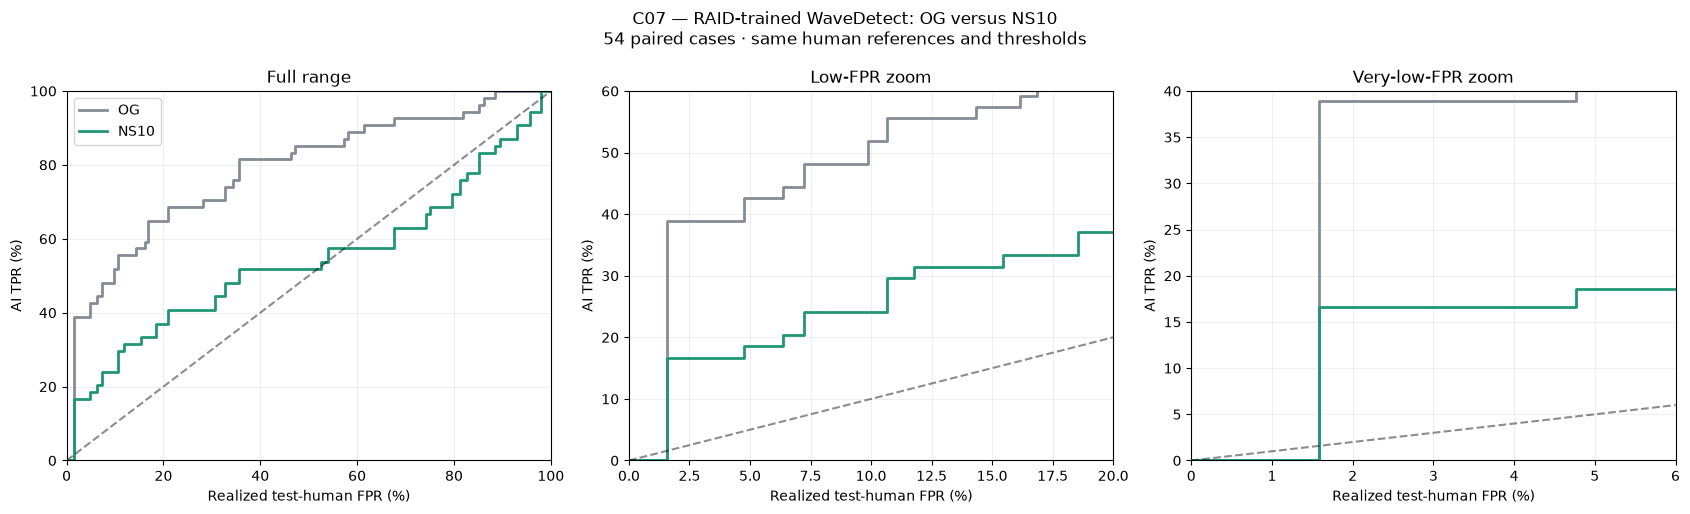

Saved all scores, thresholds, paired comparisons and figures: ../results/causal/C07_WaveDetect_RAID_OG_NS10_v1
Do not tune this detector based on the NS10 comparison. ProSSD and Binoculars are separate follow-up notebooks.


In [8]:
COLORS={'OG':'#858C96','NS10':'#209675'}
def save_figure(fig,stem):
    for folder in [OUT,ROOT/'figures']:
        folder.mkdir(exist_ok=True,parents=True)
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
fig,axs=plt.subplots(1,3,figsize=(17,5.2))
for ax,(xl,yl,title) in zip(axs,[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
    for name in COLORS:ax.step(st.test_FPR*100,st[name]*100,where='post',color=COLORS[name],lw=2,label=name)
    hi=min(xl[1],yl[1]);ax.plot([0,hi],[0,hi],'--',color='black',alpha=.45)
    ax.set(xlim=xl,ylim=yl,title=title,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
axs[0].legend()
fig.suptitle(f'C07 — RAID-trained WaveDetect: OG versus NS10\n54 paired cases · same human references and thresholds')
fig.tight_layout();save_figure(fig,'C07_WaveDetect_OG_NS10_TPR_staircase')


print('Saved all scores, thresholds, paired comparisons and figures:',OUT)
print('Do not tune this detector based on the NS10 comparison. ProSSD and Binoculars are separate follow-up notebooks.')


## Interpretation and next detectors
A decrease from OG to NS10 on this retrained detector measures transfer beyond Ghostbuster. Assess it together with ordinary held-out RAID and matched OG AUROC. The softmax output is an AI score, not an independently calibrated posterior probability. The staircase uses validation-human thresholds and realized test-human FPR; its area is not used for AUROC. AUROC is calculated from all pairwise score rankings, including ties.

The 54 texts were used during intervention development; new detector training does not make them an untouched attack-development holdout. One neural training seed is a first stress test. Retain negative results and truncation counts. ProSSD and Binoculars require their own fitting/calibration protocols rather than automatically treating every detector as a supervised classifier.


Adaptation 1/3: 100%|███████████████████████████████████████████████████████████████| 162/162 [10:05<00:00,  3.74s/it, loss=0.224]


,epoch,train_loss,validation_loss
0,1,0.83492,0.484817


Adaptation 2/3: 100%|███████████████████████████████████████████████████████████████| 162/162 [09:57<00:00,  3.69s/it, loss=0.189]


,epoch,train_loss,validation_loss
1,2,0.523805,0.568971


Adaptation 3/3: 100%|██████████████████████████████████████████████████████████████| 162/162 [10:08<00:00,  3.76s/it, loss=0.0991]


,epoch,train_loss,validation_loss
2,3,0.343351,0.467972


Adapted held-out 34: 100%|████████████████████████████████████████████████████████████████████████| 34/34 [00:03<00:00, 10.38it/s]


,detector,cases,AUROC,mean_AI_score,median_AI_score
0,Frozen,34,0.608108,0.538597,0.493935
1,Adapted,34,0.584489,0.598111,0.630554


,threshold,calibration_FPR,test_FPR,TPR,detector,target_FPR
0,0.950778,0.000000,0.019608,0.176471,Frozen,0.000
1,0.950778,0.000000,0.019608,0.176471,Frozen,0.001
2,0.950778,0.000000,0.019608,0.176471,Frozen,0.005
3,0.925230,0.009804,0.019608,0.205882,Frozen,0.010
4,0.870597,0.019608,0.058824,0.235294,Frozen,0.020
5,0.810479,0.039216,0.086667,0.264706,Frozen,0.050
6,0.711832,0.095425,0.133622,0.382353,Frozen,0.100
7,0.552540,0.198675,0.224367,0.441176,Frozen,0.200
8,0.346873,0.496043,0.522428,0.647059,Frozen,0.500
9,-inf,1.000000,1.000000,1.000000,Frozen,1.000


,comparison,metric,cases,mean_delta,ci_low,ci_high
0,Adapted_minus_Frozen,AUROC,34,-0.023619,-0.062273,0.008026


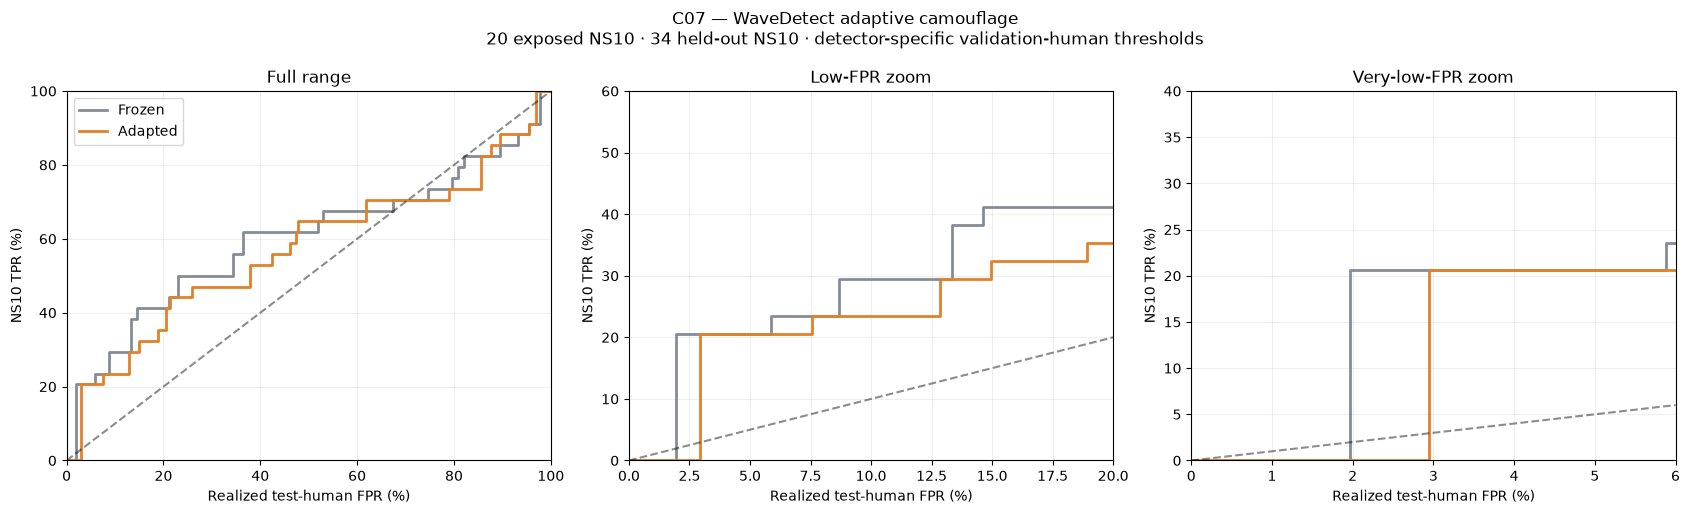

Saved: ../results/causal/C07_WaveDetect_RAID_OG_NS10_v1/adaptive_20_34_v1
The 34 are held out from detector adaptation, not from earlier intervention development. Intervals exclude split/training-seed and human-reference uncertainty.


In [9]:
# C07 adaptive camouflage — 20 exposed NS10 / 34 held-out NS10
# Uses existing C07 definitions; leaves the frozen detector files unchanged.
import copy

def run_c07_adaptation():
    AOUT = OUT / "adaptive_20_34_v1"
    AOUT.mkdir(parents=True, exist_ok=True)
    (AOUT / "scores").mkdir(exist_ok=True)

    ADAPT_SEED = 20260923
    ADAPT_EPOCHS = 3
    ADAPT_LR = 1e-5
    frozen_sha = file_sha(FINAL)

    # Stable random selection, persisted and verified on rerun.
    cases = np.array(sorted(ns.case_id.astype(str)))
    assert len(cases) == 54 and len(set(cases)) == 54
    chosen = set(np.random.default_rng(ADAPT_SEED).permutation(cases)[:20])
    split = ns[["case_id", "source_id", "domain"]].copy()
    split["role"] = np.where(
        split.case_id.astype(str).isin(chosen), "adapt20", "heldout34"
    )
    split = split.sort_values("case_id").reset_index(drop=True)
    split_path = AOUT / "split_20_34.csv"

    if split_path.exists():
        old = pd.read_csv(split_path, keep_default_na=False)
        pd.testing.assert_frame_equal(old, split, check_dtype=False)
    else:
        save_csv(split, split_path)

    adapt = ns.loc[ns.case_id.astype(str).isin(chosen)].copy()
    held = ns.loc[~ns.case_id.astype(str).isin(chosen)].copy()
    assert len(adapt) == 20 and len(held) == 34
    assert set(adapt.source_id).isdisjoint(set(held.source_id))

    fit = pd.concat([
        tr[["source_id", "domain", "text", "label"]].assign(origin="RAID_train"),
        adapt[["source_id", "domain", "text"]].assign(
            label=1, origin="NS10_adapt20"
        ),
    ], ignore_index=True)
    assert set(fit.source_id).isdisjoint(set(held.source_id))
    save_csv(fit.drop(columns="text"), AOUT / "training_manifest.csv")

    protocol = dict(
        version="C07_adaptive_v1",
        parent_contract=CONTRACT_SHA,
        frozen_model_sha=frozen_sha,
        seed=ADAPT_SEED,
        epochs=ADAPT_EPOCHS,
        lr=ADAPT_LR,
        logical_batch=BATCH,
        microbatch=MICROBATCH,
        exposed_cases=sorted(chosen),
        training="original RAID train + 20 NS10; all parameters",
        selection="minimum original RAID validation loss",
    )
    freeze(protocol, AOUT / "contract.json")
    signature = text_sha(json.dumps(protocol, sort_keys=True))
    latest = AOUT / "latest.pt"
    final_path = AOUT / "adapted_best.pt"

    # Work on a separate model; offload the existing frozen model during training.
    frozen_device = next(model.parameters()).device
    model.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()
    net = None

    try:
        random.seed(ADAPT_SEED)
        np.random.seed(ADAPT_SEED)
        torch.manual_seed(ADAPT_SEED)
        torch.cuda.manual_seed_all(ADAPT_SEED)
        net = copy.deepcopy(model).to(DEVICE)
        net.set_stage(2)

        @torch.no_grad()
        def evaluate_validation():
            net.eval()
            values = []
            for start in range(0, len(va), BATCH):
                group = va.iloc[start:start+BATCH]
                coeff = loss_coeff(group.label.to_numpy())
                total = 0.
                for j in range(0, len(group), MICROBATCH):
                    part = group.iloc[j:j+MICROBATCH]
                    with torch.autocast("cuda", dtype=torch.bfloat16):
                        logits = net(**batch_inputs(part))
                    labels = torch.tensor(
                        part.label.to_numpy(), device=DEVICE, dtype=torch.long
                    )
                    ce = nn.functional.cross_entropy(
                        logits.float(), labels, reduction="none"
                    )
                    total += float((
                        ce * torch.tensor(coeff[j:j+len(part)], device=DEVICE)
                    ).sum())
                values.append(total)
            return float(np.mean(values))

        if final_path.exists():
            saved = torch.load(
                final_path, map_location="cpu", weights_only=False
            )
            assert saved["contract"] == signature
            net.load_state_dict(saved["model"])
            del saved
            print("Loaded saved adapted detector.")
        else:
            # Always initialize from the saved selected frozen detector.
            saved = torch.load(FINAL, map_location="cpu", weights_only=False)
            assert saved["contract"] == CONTRACT_SHA
            net.load_state_dict(saved["model"])
            del saved

            optimizer = torch.optim.AdamW(
                net.parameters(), lr=ADAPT_LR,
                eps=1e-8, weight_decay=.01, foreach=False,
            )
            total_steps = math.ceil(len(fit) / BATCH) * ADAPT_EPOCHS
            scheduler = torch.optim.lr_scheduler.LambdaLR(
                optimizer, lambda step: max(0., 1-step/total_steps)
            )
            epoch0 = cursor0 = updates = seen = 0
            running = 0.
            best_loss = float("inf")
            best = None
            history = []

            if latest.exists():
                saved = torch.load(
                    latest, map_location="cpu", weights_only=False
                )
                assert saved["contract"] == signature
                net.load_state_dict(saved["model"])
                optimizer.load_state_dict(saved["optimizer"])
                scheduler.load_state_dict(saved["scheduler"])
                epoch0, cursor0 = saved["epoch"], saved["cursor"]
                updates, running, seen = (
                    saved["updates"], saved["running"], saved["seen"]
                )
                best, best_loss, history = (
                    saved["best"], saved["best_loss"], saved["history"]
                )
                restore_rng(saved["rng"])
                del saved
                print(f"Resuming epoch {epoch0+1}, row offset {cursor0}.")

            def checkpoint_adaptation(epoch, cursor):
                save_torch(dict(
                    contract=signature,
                    model=net.state_dict(),
                    optimizer=optimizer.state_dict(),
                    scheduler=scheduler.state_dict(),
                    epoch=epoch, cursor=cursor, updates=updates,
                    running=running, seen=seen,
                    best=best, best_loss=best_loss,
                    history=history, rng=rng_state(),
                ), latest)

            for epoch in range(epoch0, ADAPT_EPOCHS):
                order = np.random.default_rng(
                    ADAPT_SEED + epoch
                ).permutation(len(fit))
                begin = cursor0 if epoch == epoch0 else 0
                net.train()
                optimizer.zero_grad(set_to_none=True)

                bar = tqdm(
                    range(begin, len(fit), BATCH),
                    desc=f"Adaptation {epoch+1}/{ADAPT_EPOCHS}",
                )
                for pos in bar:
                    group = fit.iloc[order[pos:pos+BATCH]]
                    coeff = loss_coeff(group.label.to_numpy())
                    batch_loss = 0.

                    for j in range(0, len(group), MICROBATCH):
                        part = group.iloc[j:j+MICROBATCH]
                        with torch.autocast("cuda", dtype=torch.bfloat16):
                            logits = net(**batch_inputs(part))
                        labels = torch.tensor(
                            part.label.to_numpy(),
                            device=DEVICE, dtype=torch.long,
                        )
                        ce = nn.functional.cross_entropy(
                            logits.float(), labels, reduction="none"
                        )
                        loss = (
                            ce * torch.tensor(
                                coeff[j:j+len(part)], device=DEVICE
                            )
                        ).sum()
                        assert torch.isfinite(loss), "Nonfinite adaptation loss"
                        loss.backward()
                        batch_loss += float(loss.detach())

                    torch.nn.utils.clip_grad_norm_(
                        net.parameters(), 1., error_if_nonfinite=True
                    )
                    optimizer.step()
                    scheduler.step()
                    optimizer.zero_grad(set_to_none=True)
                    updates += 1
                    running += batch_loss
                    seen += 1

                    if updates % SAVE_EVERY == 0:
                        checkpoint_adaptation(
                            epoch, min(pos+BATCH, len(fit))
                        )
                    bar.set_postfix(loss=round(batch_loss, 4))

                val_loss = evaluate_validation()
                assert np.isfinite(val_loss)
                history.append(dict(
                    epoch=epoch+1,
                    train_loss=running/max(1, seen),
                    validation_loss=val_loss,
                ))
                if val_loss < best_loss:
                    best_loss = val_loss
                    best = cpu_state(net)

                running = 0.
                seen = 0
                checkpoint_adaptation(epoch+1, 0)
                save_csv(pd.DataFrame(history), AOUT / "training_history.csv")
                display(pd.DataFrame(history).tail(1))
                cursor0 = 0

            assert best is not None
            save_torch(dict(
                contract=signature, model=best,
                best_validation_loss=best_loss, history=history,
            ), final_path)
            net.load_state_dict(best)
            del optimizer, scheduler, best
            gc.collect()
            torch.cuda.empty_cache()

        net.eval()
        adapted_sha = file_sha(final_path)

        @torch.no_grad()
        def adapted_score(text):
            key = text_sha(adapted_sha + text_sha(text))
            path = AOUT / "scores" / (key + ".json")
            if path.exists():
                obj = json.loads(path.read_text())
                assert obj["model_sha"] == adapted_sha
                assert obj["text_sha"] == text_sha(text)
                return obj["AI_score"]

            rec = encode(text)
            inputs = {
                k: rec[k].unsqueeze(0).to(DEVICE)
                for k in ["input_ids", "attention_mask"]
            }
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits = net(**inputs)
            score = float(logits.float().softmax(-1)[0, 1])
            assert np.isfinite(score)
            save_json(dict(
                model_sha=adapted_sha,
                text_sha=text_sha(text), AI_score=score,
            ), path)
            return score

        # Same 34 AI cases and genre-weighted human rows for both detectors.
        mix = held.domain.value_counts(normalize=True)

        def human_reference(split_name):
            q = raid.loc[
                raid.split.eq(split_name)
                & raid.label.eq(0)
                & raid.domain.isin(mix.index)
            ].copy()
            counts = q.domain.value_counts()
            assert set(mix.index) <= set(counts.index)
            q["weight"] = [mix[d]/counts[d] for d in q.domain]
            q["Frozen"] = q.source_id.map(
                R.set_index("source_id").AI_score
            )
            assert q.Frozen.notna().all()
            q["Adapted"] = [
                adapted_score(t)
                for t in tqdm(q.text, desc=f"Adapted {split_name} humans")
            ]
            assert np.isclose(q.weight.sum(), 1)
            save_csv(
                q.drop(columns="text"),
                AOUT / f"{split_name}_human_reference.csv",
            )
            return q

        cal34 = human_reference("validation")
        human34 = human_reference("test")
        scores = held[["case_id", "source_id", "domain"]].copy()
        scores["Frozen"] = scores.case_id.map(
            N.set_index("case_id").AI_score
        )
        assert scores.Frozen.notna().all()
        scores["Adapted"] = [
            adapted_score(t)
            for t in tqdm(held.text, desc="Adapted held-out 34")
        ]
        save_csv(scores, AOUT / "heldout34_scores.csv")

        stairs = {}
        summary_rows = []
        operating_rows = []
        contributions = {}

        for name in ["Frozen", "Adapted"]:
            ai = scores[name].to_numpy()
            hs = human34[name].to_numpy()
            weights = human34.weight.to_numpy()

            area = roc_auc_score(
                np.r_[np.zeros(len(hs)), np.ones(len(ai))],
                np.r_[hs, ai],
                sample_weight=np.r_[weights, np.ones(len(ai))/len(ai)],
            )
            summary_rows.append(dict(
                detector=name, cases=len(ai), AUROC=area,
                mean_AI_score=ai.mean(), median_AI_score=np.median(ai),
            ))
            contributions[name] = (
                ((ai[:, None] > hs)
                 + .5*(ai[:, None] == hs)) * weights
            ).sum(axis=1)

            cuts = np.r_[np.inf, np.unique(cal34[name])[::-1], -np.inf]
            table = pd.DataFrame(dict(
                threshold=cuts,
                calibration_FPR=[
                    cal34.loc[cal34[name] > c, "weight"].sum()
                    for c in cuts
                ],
                test_FPR=[
                    human34.loc[human34[name] > c, "weight"].sum()
                    for c in cuts
                ],
                TPR=[(ai > c).mean() for c in cuts],
            ))
            stairs[name] = table
            save_csv(table, AOUT / f"{name}_TPR_staircase.csv")

            for target in [0, .001, .005, .01, .02, .05, .1, .2, .5, 1.]:
                row = table.loc[
                    table.calibration_FPR <= target + 1e-12
                ].iloc[-1].to_dict()
                row.update(detector=name, target_FPR=target)
                operating_rows.append(row)

        summary = pd.DataFrame(summary_rows)
        operating = pd.DataFrame(operating_rows)
        save_csv(summary, AOUT / "adaptive_summary.csv")
        save_csv(operating, AOUT / "operating_points.csv")
        display(summary.round(6))
        display(operating.round(6))

        # Paired case-bootstrap: human references and trained models fixed.
        delta = contributions["Adapted"] - contributions["Frozen"]
        rng = np.random.default_rng(ADAPT_SEED)
        ix = rng.integers(0, len(delta), size=(10000, len(delta)))
        low, high = np.quantile(delta[ix].mean(axis=1), [.025, .975])
        rebound = pd.DataFrame([dict(
            comparison="Adapted_minus_Frozen",
            metric="AUROC", cases=len(delta),
            mean_delta=delta.mean(), ci_low=low, ci_high=high,
        )])
        save_csv(rebound, AOUT / "paired_AUROC_rebound.csv")
        display(rebound.round(6))

        colors = {"Frozen": "#858C96", "Adapted": "#E1812C"}
        fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
        panels = [
            ((0, 100), (0, 100), "Full range"),
            ((0, 20), (0, 60), "Low-FPR zoom"),
            ((0, 6), (0, 40), "Very-low-FPR zoom"),
        ]
        for ax, (xl, yl, title) in zip(axs, panels):
            for name, table in stairs.items():
                ax.step(
                    table.test_FPR*100, table.TPR*100,
                    where="post", color=colors[name], lw=2, label=name,
                )
            hi = min(xl[1], yl[1])
            ax.plot([0, hi], [0, hi], "--", color="black", alpha=.45)
            ax.set(
                xlim=xl, ylim=yl, title=title,
                xlabel="Realized test-human FPR (%)",
                ylabel="NS10 TPR (%)",
            )
            ax.grid(alpha=.2)
        axs[0].legend()
        fig.suptitle(
            "C07 — WaveDetect adaptive camouflage\n"
            "20 exposed NS10 · 34 held-out NS10 · "
            "detector-specific validation-human thresholds"
        )
        fig.tight_layout()
        for folder in [AOUT, ROOT / "figures"]:
            folder.mkdir(parents=True, exist_ok=True)
            for ext in ["png", "pdf"]:
                fig.savefig(
                    folder / f"C07_adaptive_20_34_TPR_staircase.{ext}",
                    dpi=300, bbox_inches="tight",
                )
        plt.show()
        plt.close(fig)

        print("Saved:", AOUT)
        print(
            "The 34 are held out from detector adaptation, not from earlier "
            "intervention development. Intervals exclude split/training-seed "
            "and human-reference uncertainty."
        )
        return summary, scores, rebound

    finally:
        if net is not None:
            net.to("cpu")
            del net
        gc.collect()
        torch.cuda.empty_cache()
        model.to(frozen_device)
        model.eval()

adaptive_summary, adaptive_scores, adaptive_rebound = run_c07_adaptation()